# Прогнозирование продаж в магазинах офлаин-ритейлера в США <a class="tocSkip">

В качестве экзаменационного задания вам предстоит построить модель прогнозирования спроса(продаж) на товары в магазинах офлаин-ритейлера в США . Всего в датасете 3 магазина, в каждом магазине по 15 артикулов (товаров). Вам нужно выбрать 1 магазин (любой из 3).

Прогнозировать продажи нужно на неделю, на месяц и на квартал. Пользоваться сторонними библиотеками с соответствующими реализациями моделей можно.

В качестве дополнительной информации вам переданы данные о цене товара (меняются раз в неделю, а также о праздниках в США).

# **Практическое задание №1 - срок к 24.11. Прогнозирование с помощью классических методов.**


**1.1 Реализовать класс для обучения и оценки качества прогноза на неделю, на месяц и на квартал с помощью классических методов:**

1) Должен предобрабатывать исходные данные в удобный формат;

2) Должен обучаться для задачи прогнозирования;

3) В качестве моделей должны использоваться классические модели, которые изучали в лекциях 2-5.

4) Должен оценивать качество своих прогнозов;

5) Код должен быть написан по PEP-8;


**1.2 Подготовить отчет в виде jupyter ноутбука:**

1) Все методы должны быть реализованы в классе, в ноутбуке только вызов методов, визуализация и комментарии;

2) Для прогнозов использованы как минимум 3 любые классические модели, которые изучали в лекциях 2-5

3) Отчет содержит текстовое описание реализованного класса и основных методов, продемонстрирован результат работы этих методов.

4) Отчет содержит визуализации результатов прогнозов и оценки метрик качества на неделю, на месяц и на квартал

5) Отчет содержит текстовые ответы на следующие вопросы:

 * Какие методы предобработки данных вы использовали? Почему пробовали именно их?

 * Какие модели пробовали? Почему пробовали именно их?

 * Как вы проверяете качество модели? На каких данных? Какие метрики используюте? Чем обусловлен выбор именно этих метрик?

 * Какая подход из испробованных самый оптимальный с точки зрения качества прогнозирования?

 * Какое итоговое качество модели на тестовом датасете?


# **Практическое задание №2 - срок к 4.12. Прогнозирование с помощью современных методов.**

**2.1 Реализовать класс для обучения и оценки качества прогноза на неделю, на месяц и на квартал с помощью современных методов:**

**2.2 Подготовить отчет в виде jupyter ноутбука:**


Подпункты 2.1 и 2.2 повторяют полностью подпункты 1.1 и 1.2, кроме единственного исключения - в качестве модели достаточно попробовать только одну - либо градиентный бустинг, либо нейронную сеть, либо обе (по желанию).

# **Итоговый проект - срок к 11.12. Реализовать итоговый класс, в котором выбрана 1-2 лучшие по вашему мнению модели, который умеет:**

1) предобрабатывать исходные данные в удобный формат;

2) обучаться для задачи прогнозирования;

3) оценивать качество своих прогнозов;

4) сохранять модели и подгружать их;

5) Прогнозировать продажи на неделю, на месяц и на квартал.

Должна быть рабочая программа, которая делает инференс (прогнозирование на произвольном тестовом датасете (аналогично тому, который есть у вас)) без обучения (предобученные модели сохранены в файлы и подгружаются в тексте класса)

Графики продаж артикулов по магазинам:

---

# Отчёт по практическому заданию №1

**Магазин:** `STORE_1` (15 товаров, ежедневные продажи
с 29.01.2011 по 21.01.2016).

**Класс:** `SalesForecaster` в файле
[`sales_forecast.py`](sales_forecast.py). В ноутбуке — только вызовы
методов класса, визуализация и пояснения.

**Горизонты:** неделя (7 дней), месяц (30 дней), квартал (90 дней).

## 1. Импорты

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sales_forecast import HORIZONS, MODEL_TITLES, SalesForecaster

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (14, 5)

## 2. Загрузка и краткий анализ данных

`shop_sales.csv` — продажи, `shop_sales_dates.csv` — календарь
с датами и днями недели. Цены, праздники и кэшбэк в моделях не
использую, поэтому они нужны только для справки.

In [2]:
forecaster = SalesForecaster(store_id="STORE_1", data_dir="data")
forecaster.load_data()

print("Продажи:", forecaster.sales.shape)
print("Календарь:", forecaster.calendar.shape)
display(forecaster.sales.head())

Продажи: (81855, 4)
Календарь: (1819, 14)


,item_id,store_id,date_id,cnt
0,STORE_2_085,STORE_2,1,3
1,STORE_2_085,STORE_2,2,8
2,STORE_2_085,STORE_2,3,0
3,STORE_2_085,STORE_2,4,3
4,STORE_2_085,STORE_2,5,0


In [3]:
store_sales = forecaster.sales[
    forecaster.sales["store_id"] == forecaster.store_id
]
print("Товаров:", store_sales["item_id"].nunique())
print("Дней:", store_sales["date_id"].nunique())
print("Средние продажи в день:", round(store_sales["cnt"].mean(), 2))
print("Доля нулевых продаж:", f"{(store_sales['cnt'] == 0).mean():.1%}")

Товаров: 15
Дней: 1819
Средние продажи в день: 16.47
Доля нулевых продаж: 26.6%


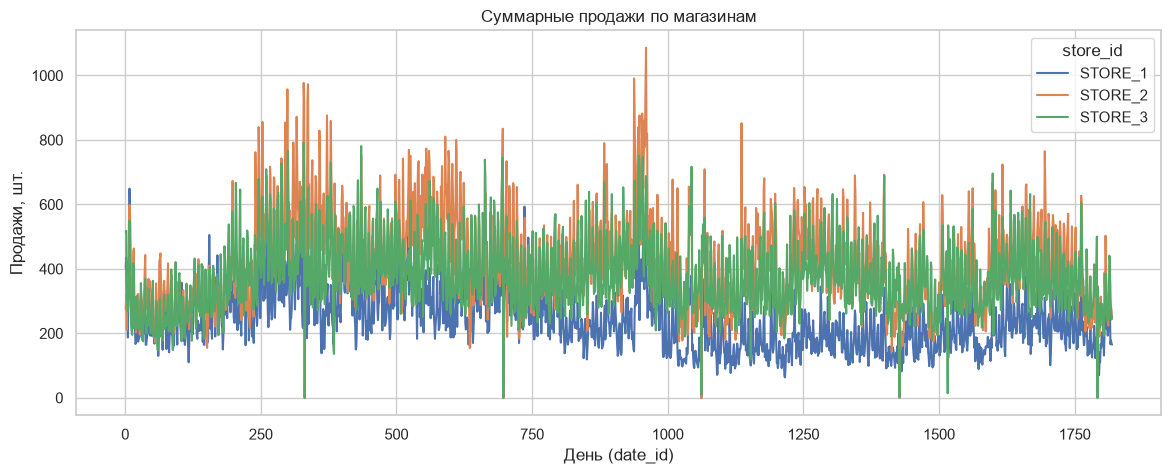

In [4]:
store_daily = (
    forecaster.sales.groupby(["store_id", "date_id"])["cnt"]
    .sum()
    .reset_index()
)
fig, ax = plt.subplots()
sns.lineplot(
    data=store_daily,
    x="date_id",
    y="cnt",
    hue="store_id",
    ax=ax,
)
ax.set(
    title="Суммарные продажи по магазинам",
    xlabel="День (date_id)",
    ylabel="Продажи, шт.",
)
plt.show()

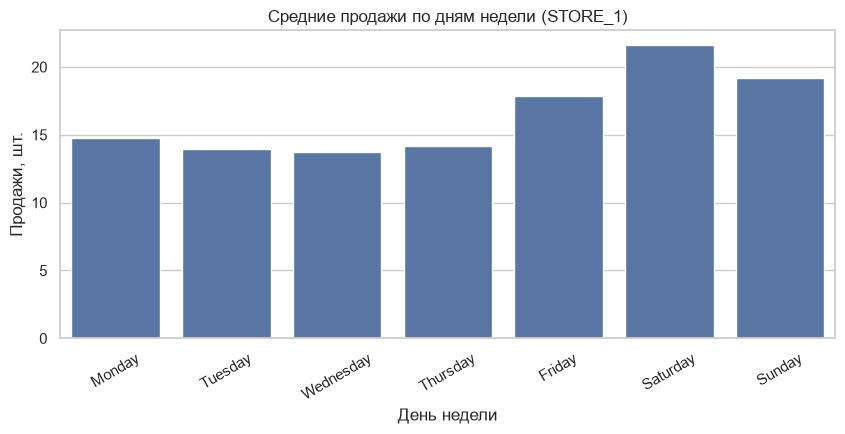

In [5]:
calendar = forecaster.calendar.copy()
calendar["date"] = pd.to_datetime(calendar["date"])
merged = store_sales.merge(
    calendar[["date_id", "weekday"]],
    on="date_id",
    how="left",
)
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
weekday_profile = merged.groupby("weekday", as_index=False)["cnt"].mean()
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(
    data=weekday_profile,
    x="weekday",
    y="cnt",
    order=weekday_order,
    ax=ax,
)
ax.set(
    title="Средние продажи по дням недели (STORE_1)",
    xlabel="День недели",
    ylabel="Продажи, шт.",
)
ax.tick_params(axis="x", rotation=30)
plt.show()

## 3. Описание класса `SalesForecaster`

Класс лежит в `sales_forecast.py`, старалась писать по PEP-8
(проверяла через `flake8`, длина строки ≤ 79). Основные методы:

| Метод | Назначение |
|---|---|
| `load_data()` | читает три таблицы |
| `preprocess()` | объединяет данные и строит признаки |
| `split()` | делит ряд на обучение и тест по времени |
| `fit()` | обучает модели для каждого товара |
| `predict(model, horizon)` | прогноз на горизонт в днях |
| `evaluate()` | метрики по товаро-дням |
| `evaluate_aggregated()` | метрики по суммарному ряду магазина |
| `forecast_totals()` | прогноз и факт по товарам |
| `best_model(horizon)` | лучшая модель на горизонте |

Реализованы три классические модели:

| Модель | Идея |
|---|---|
| Holt-Winters (ETS) | экспоненциальное сглаживание с трендом и сезонностью 7 |
| ARIMA(1,1,1) | ARIMA без сезонной части |
| SARIMA(1,1,1)(0,1,1,7) | ARIMA с недельной сезонностью и разностями |

Если оптимизация ETS, ARIMA или SARIMA не сходится, модель
откатывается на повтор последней недели.

## 4. Предобработка и разделение данных

`preprocess()` фильтрует магазин, присоединяет календарь по `date_id`,
приводит дату к `datetime`, сортирует по товару и дате и
переименовывает `cnt` в `y`. Цены, праздники и кэшбэк не использую:
выбранные модели работают только с рядом продаж.

In [6]:
forecaster.preprocess()
print("Строк после предобработки:", len(forecaster.data))
display(forecaster.data.head())
print("Пропуски:")
display(
    forecaster.data[["y"]]
    .isna()
    .sum()
    .to_frame("Пропуски")
    .T
)

Строк после предобработки: 27285


,item_id,store_id,date_id,y,date
0,STORE_1_064,STORE_1,1,0,2011-01-29
1,STORE_1_064,STORE_1,2,1,2011-01-30
2,STORE_1_064,STORE_1,3,0,2011-01-31
3,STORE_1_064,STORE_1,4,0,2011-02-01
4,STORE_1_064,STORE_1,5,0,2011-02-02


Пропуски:


,y
Пропуски,0


In [7]:
forecaster.split()
train = forecaster.train
test = forecaster.test
print(
    f"Обучение: {train['date'].min():%d.%m.%Y} — "
    f"{train['date'].max():%d.%m.%Y}, строк: {len(train)}"
)
print(
    f"Тест:     {test['date'].min():%d.%m.%Y} — "
    f"{test['date'].max():%d.%m.%Y}, строк: {len(test)}"
)

Обучение: 29.01.2011 — 23.10.2015, строк: 25935
Тест:     24.10.2015 — 21.01.2016, строк: 1350


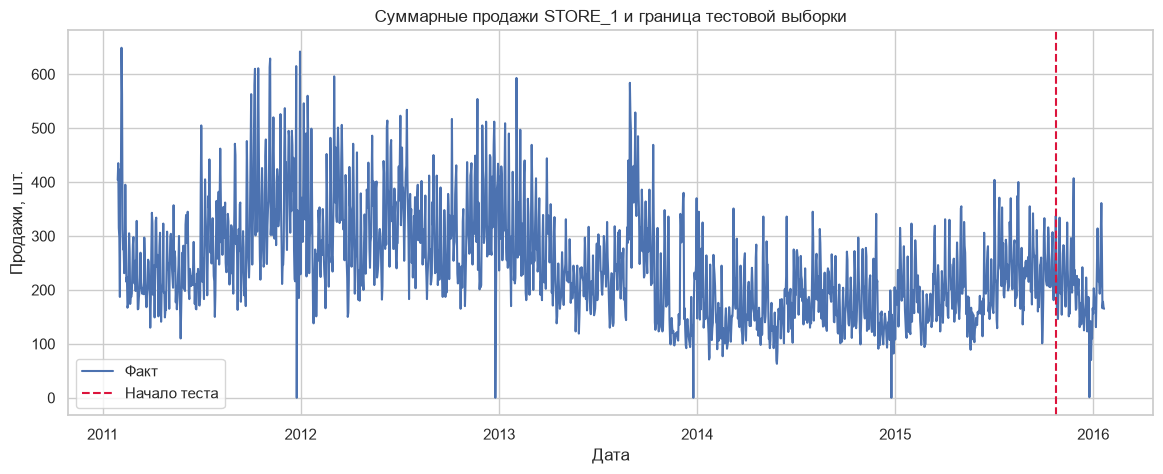

In [8]:
daily_total = forecaster.data.groupby("date", as_index=False)["y"].sum()
fig, ax = plt.subplots()
ax.plot(daily_total["date"], daily_total["y"], label="Факт")
ax.axvline(
    forecaster.test_start,
    color="crimson",
    linestyle="--",
    label="Начало теста",
)
ax.set(
    title="Суммарные продажи STORE_1 и граница тестовой выборки",
    xlabel="Дата",
    ylabel="Продажи, шт.",
)
ax.legend()
plt.show()

## 5. Обучение и оценка качества

Тест — последние 90 дней. Для недели беру первые 7 дней теста, для
месяца — 30, для квартала — все 90. Считаю несколько метрик, потому
что одной для такой задачи мало. MAE показывает среднюю ошибку в
штуках, RMSE сильнее штрафует большие промахи, WAPE удобно смотреть
в процентах от общего объёма продаж, sMAPE помогает сравнивать товары
с разным масштабом, а bias показывает, есть ли систематический
недопрогноз или перепрогноз. Основная метрика — WAPE: в продажах
много нулей, и обычный MAPE на них ломается. Дополнительно смотрю
метрики по товаро-дням и по суммарному ряду магазина — второе ближе
к тому, что важно бизнесу.

In [9]:
start = time.time()
forecaster.fit()
print(f"Обучение: {time.time() - start:.1f} с")
print("Модели:", ", ".join(forecaster.models))

Обучение: 39.1 с
Модели: holt_winters, arima, sarima


In [10]:
metrics = forecaster.evaluate()
columns = [
    "model_title",
    "horizon_name",
    "MAE",
    "RMSE",
    "WAPE",
    "sMAPE",
    "bias",
    "total_error_pct",
]
print("Метрики по товаро-дням:")
display(metrics[columns].round(3))

agg_metrics = forecaster.evaluate_aggregated()
print("Метрики по суммарному ряду магазина:")
display(agg_metrics[columns].round(3))

Метрики по товаро-дням:


,model_title,horizon_name,MAE,RMSE,WAPE,sMAPE,bias,total_error_pct
0,Holt-Winters (ETS),week,4.180,6.855,0.284,0.762,1.499,10.166
1,Holt-Winters (ETS),month,4.679,7.777,0.310,0.794,1.355,8.970
2,Holt-Winters (ETS),quarter,7.016,16.363,0.520,0.860,2.731,20.241
3,"ARIMA(1,1,1)",week,5.543,9.969,0.376,0.817,1.514,10.268
4,"ARIMA(1,1,1)",month,5.397,9.390,0.357,0.819,0.887,5.869
5,"ARIMA(1,1,1)",quarter,7.235,16.007,0.536,0.864,2.453,18.184
6,"SARIMA(1,1,1)(0,1,1,7)",week,4.299,6.851,0.292,0.766,1.547,10.493
7,"SARIMA(1,1,1)(0,1,1,7)",month,4.700,7.888,0.311,0.789,1.521,10.067
8,"SARIMA(1,1,1)(0,1,1,7)",quarter,7.177,17.511,0.532,0.853,3.279,24.307


Метрики по суммарному ряду магазина:


,model_title,horizon_name,MAE,RMSE,WAPE,sMAPE,bias,total_error_pct
0,Holt-Winters (ETS),week,34.353,38.438,0.155,0.165,22.482,10.166
1,Holt-Winters (ETS),month,28.587,33.849,0.126,0.131,20.332,8.970
2,Holt-Winters (ETS),quarter,54.670,71.032,0.270,0.267,40.963,20.241
3,"ARIMA(1,1,1)",week,59.186,64.874,0.268,0.268,22.706,10.268
4,"ARIMA(1,1,1)",month,47.686,55.878,0.210,0.212,13.302,5.869
5,"ARIMA(1,1,1)",quarter,62.039,74.085,0.307,0.304,36.801,18.184
6,"SARIMA(1,1,1)(0,1,1,7)",week,33.931,38.406,0.153,0.164,23.204,10.493
7,"SARIMA(1,1,1)(0,1,1,7)",month,30.269,35.465,0.134,0.138,22.819,10.067
8,"SARIMA(1,1,1)(0,1,1,7)",quarter,61.040,77.234,0.302,0.292,49.192,24.307


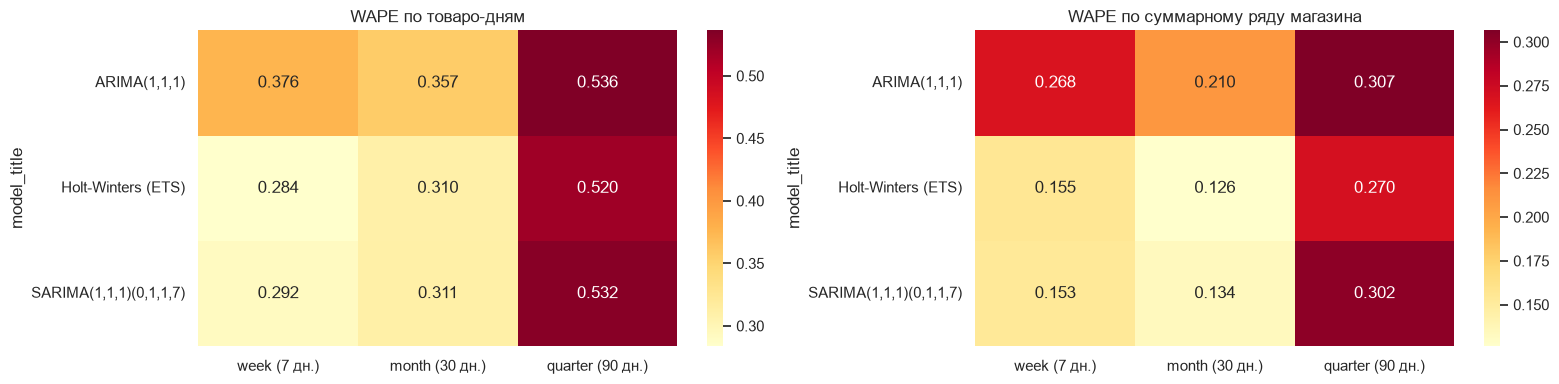

In [11]:
pivot_item = forecaster.metrics_pivot("WAPE")
pivot_item = pivot_item[["week", "month", "quarter"]]
pivot_item.columns = [f"{c} ({HORIZONS[c]} дн.)" for c in pivot_item.columns]

pivot_agg = agg_metrics.pivot_table(
    index="model_title",
    columns="horizon_name",
    values="WAPE",
)
pivot_agg = pivot_agg[["week", "month", "quarter"]]
pivot_agg.columns = [f"{c} ({HORIZONS[c]} дн.)" for c in pivot_agg.columns]

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.heatmap(
    pivot_item,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    ax=axes[0],
)
axes[0].set_title("WAPE по товаро-дням")
sns.heatmap(
    pivot_agg,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    ax=axes[1],
)
axes[1].set_title("WAPE по суммарному ряду магазина")
plt.tight_layout()
plt.show()

## 6. Визуализация прогнозов

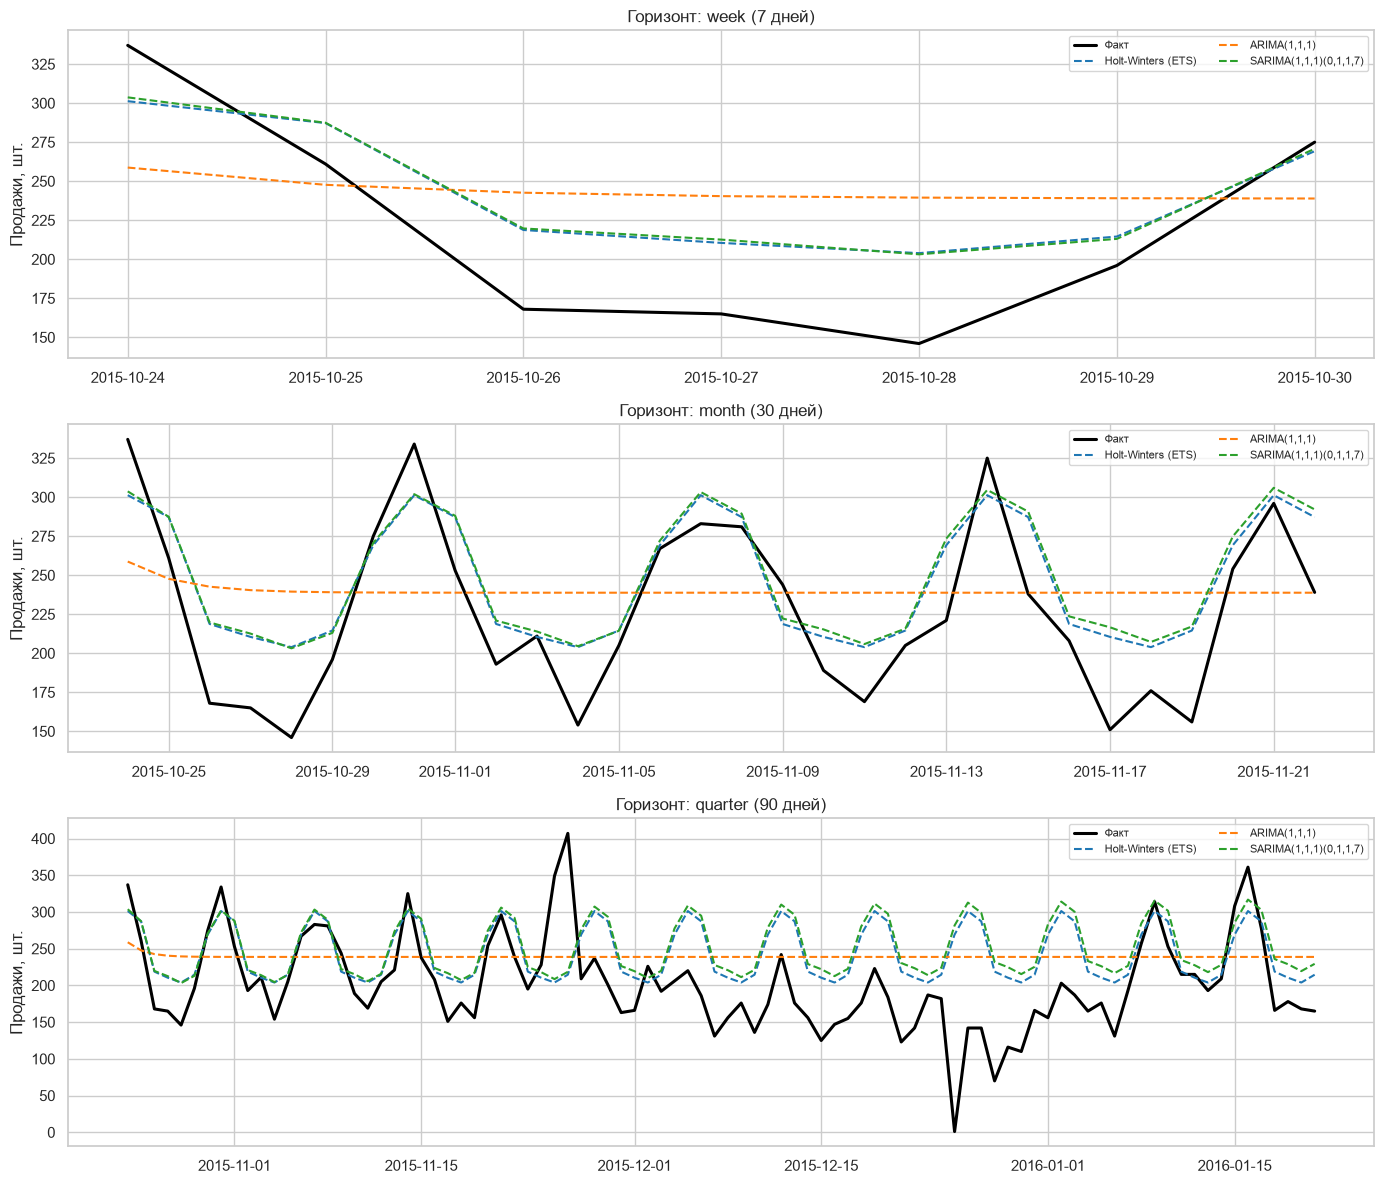

In [12]:
colors = sns.color_palette("tab10", n_colors=len(forecaster.models))
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for ax, (name, horizon) in zip(
    axes, sorted(HORIZONS.items(), key=lambda item: item[1])
):
    actual = forecaster.data.groupby("date", as_index=False)["y"].sum()
    actual = actual[actual["date"] >= forecaster.test_start]
    actual = actual.head(horizon)
    ax.plot(
        actual["date"],
        actual["y"],
        color="black",
        linewidth=2.2,
        label="Факт",
    )
    for color, model in zip(colors, forecaster.models):
        daily = forecaster.aggregate_forecast(model, horizon)
        ax.plot(
            daily["date"],
            daily["forecast"],
            linestyle="--",
            color=color,
            label=MODEL_TITLES[model],
        )
    ax.set_title(f"Горизонт: {name} ({horizon} дней)")
    ax.set_ylabel("Продажи, шт.")
    ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

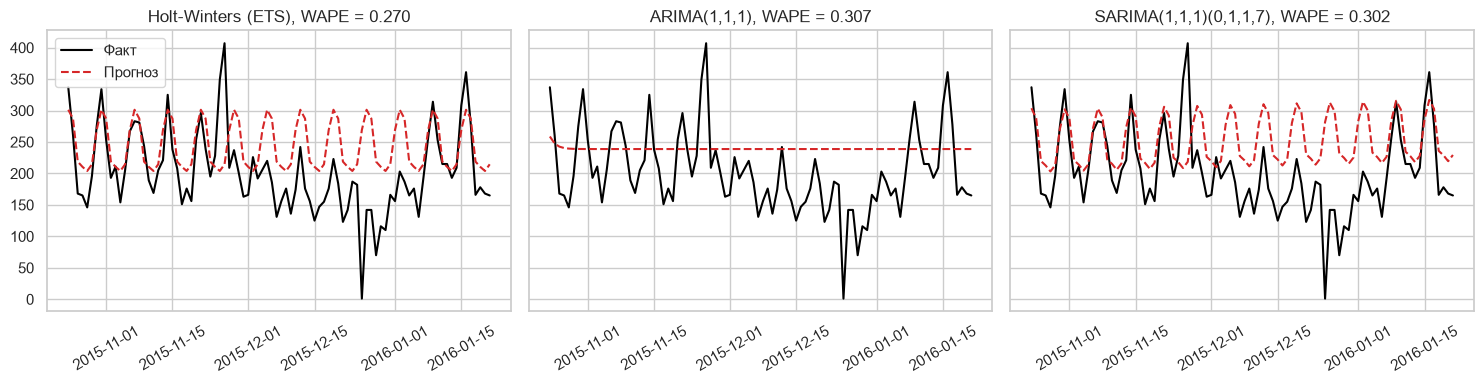

In [13]:
models = list(forecaster.models)
fig, axes = plt.subplots(
    1,
    len(models),
    figsize=(5 * len(models), 4),
    sharey=True,
)
actual = forecaster.data.groupby("date", as_index=False)["y"].sum()
actual = actual[actual["date"] >= forecaster.test_start].head(90)
for ax, model in zip(axes, models):
    daily = forecaster.aggregate_forecast(model, 90)
    ax.plot(actual["date"], actual["y"], color="black", label="Факт")
    ax.plot(
        daily["date"],
        daily["forecast"],
        color="tab:red",
        linestyle="--",
        label="Прогноз",
    )
    wape = agg_metrics[
        (agg_metrics["model"] == model)
        & (agg_metrics["horizon"] == 90)
    ]["WAPE"].iloc[0]
    ax.set_title(f"{MODEL_TITLES[model]}, WAPE = {wape:.3f}")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend()
plt.tight_layout()
plt.show()

## 7. Итоговые прогнозы на неделю, месяц и квартал

Прогноз лучшей модели (Holt-Winters) в разрезе товаров и итог по магазину.

In [14]:
best_model = forecaster.best_model(90)
totals_frames = []
summary_rows = []
for name, horizon in sorted(HORIZONS.items(), key=lambda item: item[1]):
    totals = forecaster.forecast_totals(best_model, horizon)
    totals["horizon"] = name
    totals_frames.append(totals)
    fact = totals["fact"].sum()
    forecast = totals["forecast"].sum()
    summary_rows.append(
        {
            "Горизонт": f"{name} ({horizon} дн.)",
            "Факт, шт.": round(fact, 1),
            "Прогноз, шт.": round(forecast, 1),
            "Ошибка, %": round((forecast - fact) / fact * 100, 2),
        }
    )
display(pd.DataFrame(summary_rows))

,Горизонт,"Факт, шт.","Прогноз, шт.","Ошибка, %"
0,week (7 дн.),1548,1705.4,10.17
1,month (30 дн.),6800,7410.0,8.97
2,quarter (90 дн.),18214,21900.7,20.24


In [15]:
all_totals = pd.concat(totals_frames, ignore_index=True)
forecast_table = all_totals.pivot(
    index="item_id",
    columns="horizon",
    values="forecast",
)
forecast_table = forecast_table[["week", "month", "quarter"]]
forecast_table.columns = [
    f"Неделя, {HORIZONS['week']} дн.",
    f"Месяц, {HORIZONS['month']} дн.",
    f"Квартал, {HORIZONS['quarter']} дн.",
]
display(forecast_table.round(1))

,"Неделя, 7 дн.","Месяц, 30 дн.","Квартал, 90 дн."
item_id,,,
STORE_1_064,1.1,5.0,14.1
STORE_1_065,2.5,11.0,32.7
STORE_1_090,582.5,2534.5,7472.5
STORE_1_252,126.4,548.9,1623.2
STORE_1_325,35.7,155.6,459.2
STORE_1_339,18.4,80.5,237.1
STORE_1_376,4.1,18.2,53.5
STORE_1_546,19.7,86.7,254.3
STORE_1_547,39.7,174.3,510.4


## 8. Ответы на вопросы задания

### 8.1. Какие методы предобработки использовали и почему?

Я объединила продажи с календарём по `date_id`, чтобы появилась
нормальная дата, а не просто номер дня. Дату привела к `datetime`,
отсортировала по товару и дате. Цены, праздники и кэшбэк не
использовала: ETS, ARIMA и SARIMA работают с одним рядом продаж и
не принимают экзогенные признаки. Если бы делала регрессию, эти
данные могли бы пригодиться. Делила по времени: последние 90 дней
оставила на тест, чтобы не было утечки будущего в обучение.

### 8.2. Какие модели пробовали и почему?

Я попробовала три классические модели. **Holt-Winters (ETS)** — это
экспоненциальное сглаживание с трендом и недельной сезонностью. Для
розничного ряда с недельным циклом оно подходит лучше всего.
**ARIMA(1,1,1)** взяла как базовую ARIMA без сезонности, чтобы
понять, даёт ли сезонность вообще выигрыш. **SARIMA(1,1,1)(0,1,1,7)** —
та же ARIMA, но с недельной сезонностью и разностями. Она должна
ловить повторяющийся недельный рисунок

### 8.3. Как проверяете качество, на каких данных и почему такие метрики?

Проверяю на отложенной тестовой выборке последних 90 днях
(24.10.2015–21.01.2016), обучение идёт на всех более ранних данных.
MAE считаю, чтобы понимать ошибку в штуках, RMSE, чтобы видеть
крупные промахи, WAPE как основную метрику, потому что он
устойчив к нулям и показывает ошибку относительно общего объёма
продаж. sMAPE добавила для сравнения товаров разного масштаба,
bias, чтобы проверить, нет ли систематического смещения. MAPE не
использую, тк в рядах много нулевых продаж, и она даёт слишком
нестабильные значения. Метрики смотрю и по товаро-дням, и по
суммарному ряду магазина. Второй разрез ближе к бизнесу

### 8.4. Какой подход самый оптимальный?

Лучший результат по товаро-дням на всех горизонтах у **Holt-Winters
(ETS)**: WAPE 0.28 на неделе, 0.31 на месяце и 0.52 на
квартале. На суммарном ряде магазина WAPE 0.16, 0.13 и 0.27.
SARIMA близка по качеству, но по товаро-дням на неделе и месяце
немного уступает ETS. На квартале качество падает из-за
праздничного сезона и накопления ошибки при многошаговом прогнозе

### 8.5. Какое итоговое качество на тестовом датасете?

Для Holt-Winters (ETS): WAPE по товаро-дням - **28.4%**, **31.0%**
и **52.0%** на неделю, месяц и квартал. WAPE по суммарному ряду
магазина - **15.5%**, **12.6%** и **27.0%**. Суммарная ошибка
прогноза по магазину: **+10.2%** на неделе, **+9.0%** на месяце и
**+20.2%** на квартале. На неделе и месяце качество приемлемое, на
квартале ожидаемо ниже.

## 9. Заключение

В итоге получился класс `SalesForecaster`, который сам загружает данные,
делает из них удобную таблицу, делит ряд на обучение и тест, обучает
три классические модели и считает метрики. Для недели, месяца и
квартала я использовала Holt-Winters, ARIMA и SARIMA.

Лучше всего показал себя Holt-Winters: на неделе и месяце ошибка
получилась нормальной, на квартале заметно хуже, но это ожидаемо —
там праздничный сезон и ошибка накапливается. SARIMA оказалась
близко, но чуть хуже, а ARIMA без сезонности проиграла сильнее
всего. Похоже, для этих данных недельный цикл действительно важен.